# Лабораторная работа 1. Численные методы линейной алгебры в задаче МНК

**Команда:** _ФИО 1_, _ФИО 2_, _ФИО 3_ (группа ____)

**Цель:** выяснить, как ранг и обусловленность матрицы данных влияют на решение МНК. Сравниваем метод Гаусса, метод Зейделя и SVD, затем изучаем PCR и ridge.

## 1. Данные и постановка задачи

**Данные:** California Housing, StatLib (Pace, Barry. *Sparse spatial autoregressions*. Statistics & Probability Letters, 1997). Файл `cal_housing.data` приложен к работе; в Colab его нужно загрузить рядом с ноутбуком.

Одна строка — один квартал Калифорнии (перепись 1990 года), всего 20 640 строк, пропусков нет.

| Переменная | Смысл |
|---|---|
| `longitude`, `latitude` | координаты квартала |
| `housingMedianAge` | медианный возраст домов |
| `totalRooms`, `totalBedrooms` | число комнат и спален |
| `population`, `households` | население и число домохозяйств |
| `medianIncome` | медианный доход, десятки тыс. $ |
| **`medianHouseValue`** | **отклик**: медианная цена дома, сотни тыс. $ |

8 количественных признаков, отклик количественный и не вычисляется из признаков.

**Задача:** $\min_\beta\|X\beta-y\|_2^2$, что равносильно нормальным уравнениям $A\beta=b$, где $A=X^TX$, $b=X^Ty$. Первый столбец $X$ — единицы (свободный член). Качество измеряем по RMSE на test.

**Теория:**
* $\kappa(X)=\sigma_{\max}/\sigma_{\min}$ и $\kappa(X^TX)=\kappa(X)^2$; при решении системы теряется около $\log_{10}\kappa$ верных знаков из 16.
* Численный ранг — число $\sigma_i>\sigma_{\max}\cdot\max(n,p)\cdot\varepsilon$, где $\varepsilon\approx2.2\cdot10^{-16}$.
* Разложение Холецкого существует, только если $A$ симметрична и положительно определена.
* Метод Зейделя $x_{k+1}=Tx_k+c$ сходится тогда и только тогда, когда $\rho(T)<1$, ошибка убывает как $\rho^k$. Для положительно определённой $A$ он сходится всегда.
* SVD: $\beta=V\Sigma^{-1}U^Ty$. Метод работает с $\kappa(X)$, а не $\kappa(X)^2$, и подходит при неполном ранге.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.linalg as sla
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

SEED, EPS = 42, np.finfo(float).eps
pd.set_option('display.float_format', '{:.4g}'.format)

FEATURES = ['longitude', 'latitude', 'housingMedianAge', 'totalRooms',
            'totalBedrooms', 'population', 'households', 'medianIncome']
df = pd.read_csv('cal_housing.data', header=None, names=FEATURES + ['y'])
df['y'] /= 1e5
print(df.shape, '| пропусков:', df.isna().sum().sum())
df.describe().T[['mean', 'std', 'min', 'max']]

(20640, 9) | пропусков: 0


,mean,std,min,max
longitude,-119.6,2.004,-124.3,-114.3
latitude,35.63,2.136,32.54,41.95
housingMedianAge,28.64,12.59,1,52
totalRooms,2636,2182,2,3.932e+04
totalBedrooms,537.9,421.2,1,6445
population,1425,1132,3,3.568e+04
households,499.5,382.3,1,6082
medianIncome,3.871,1.9,0.4999,15
y,2.069,1.154,0.15,5


## 2. Подготовка train/test

Данные делим один раз (80/20, seed 42). Стандартизацию обучаем только на train. Свободный член — столбец единиц во всех экспериментах.

In [2]:
F_raw, F_raw_te, y, y_te = train_test_split(df[FEATURES].values, df['y'].values, test_size=0.2, random_state=SEED)
sc = StandardScaler().fit(F_raw)
F, F_te = sc.transform(F_raw), sc.transform(F_raw_te)

ones = lambda M: np.column_stack([np.ones(len(M)), M])
X, X_te = ones(F), ones(F_te)                 # стандартизованные
X_raw, X_raw_te = ones(F_raw), ones(F_raw_te)  # исходные
A, b = X.T @ X, X.T @ y
A_raw, b_raw = X_raw.T @ X_raw, X_raw.T @ y
n, p = X.shape

def rmse(y, y_pred):
    return np.sqrt(np.mean((y - y_pred) ** 2))

def rank(s, shape):
    return int(np.sum(s > s[0] * max(shape) * EPS))

def metrics(beta, X=X, X_te=X_te):
    return {'||beta||': np.linalg.norm(beta),
            'остаток НУ': np.linalg.norm(X.T @ (X @ beta - y)) / np.linalg.norm(X.T @ y),
            'остаток МНК': np.linalg.norm(X @ beta - y) / np.linalg.norm(y),
            'RMSE train': rmse(y, X @ beta), 'RMSE test': rmse(y_te, X_te @ beta)}

## 3. Диагностика матрицы данных

исходная sigma: [5.072e+05 6.960e+04 2.239e+04 1.005e+04 6.635e+03 1.447e+03 2.201e+02
 1.692e+02 9.971e-01]
стандартизованная sigma: [253.906 177.638 133.231 128.499 116.402  49.29   36.562  27.637  15.573]


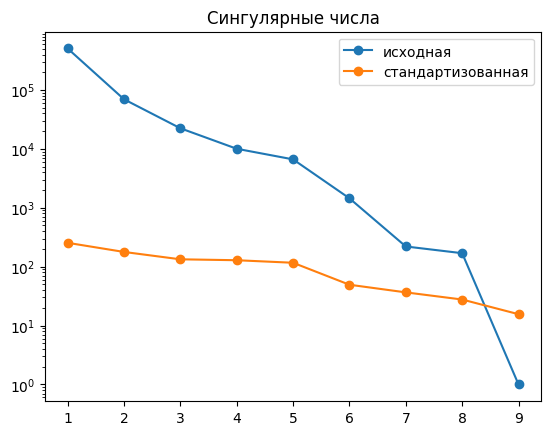

,ранг,допуск,kappa(X),kappa(X^T X)
исходная,9,1.86e-06,5.087e+05,2.588e+11
стандартизованная,9,9.309e-10,16.3,265.8


In [3]:
rows = {}
for name, M in [('исходная', X_raw), ('стандартизованная', X)]:
    s = np.linalg.svd(M, compute_uv=False)
    rows[name] = {'ранг': rank(s, M.shape), 'допуск': s[0] * max(M.shape) * EPS,
                  'kappa(X)': s[0] / s[-1], 'kappa(X^T X)': np.linalg.cond(M.T @ M)}
    print(name, 'sigma:', np.array2string(s, precision=3))
    plt.semilogy(range(1, p + 1), s, 'o-', label=name)
plt.title('Сингулярные числа'); plt.legend(); plt.show()
pd.DataFrame(rows).T

Разница корреляций до и после стандартизации: 1.965094753586527e-14
Собственные числа R: [0.015 0.046 0.081 0.147 0.821 1.075 1.911 3.904]


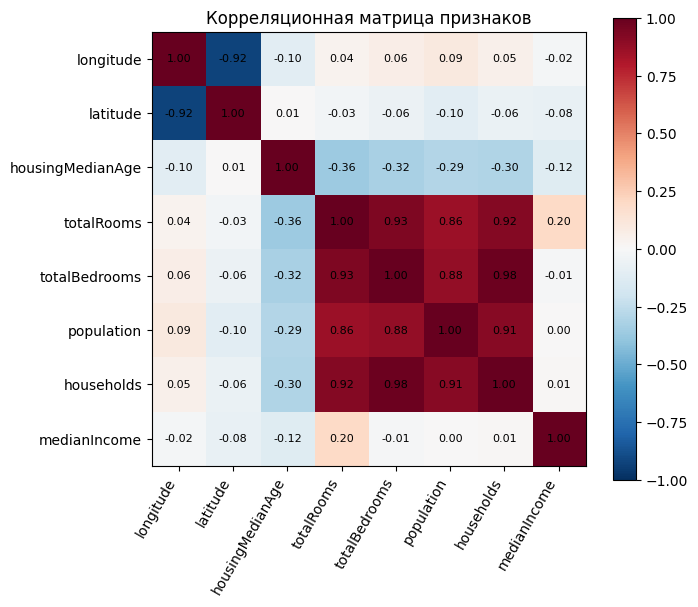

In [4]:
R = np.corrcoef(F, rowvar=False)
print('Разница корреляций до и после стандартизации:', np.abs(np.corrcoef(F_raw, rowvar=False) - R).max())
print('Собственные числа R:', np.round(np.linalg.eigvalsh(R), 3))
plt.figure(figsize=(7, 6))
plt.imshow(R, cmap='RdBu_r', vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(8), FEATURES, rotation=60, ha='right'); plt.yticks(range(8), FEATURES)
for i in range(8):
    for j in range(8):
        plt.text(j, i, f'{R[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.title('Корреляционная матрица признаков'); plt.show()

**Вывод.**
* Обе матрицы имеют полный ранг 9.
* До стандартизации $\kappa(X^TX)\approx2.6\cdot10^{11}$ (можно потерять ~11 знаков), после — 266. Причина — разные масштабы признаков. Видно, что $\kappa(X^TX)=\kappa(X)^2$.
* Корреляции стандартизация не меняет (разница ~$10^{-14}$), поэтому матрица показана одна.
* Есть сильная мультиколлинеарность: `totalRooms`, `totalBedrooms`, `population` и `households` коррелируют на 0.86–0.98, а `latitude`–`longitude` дают −0.92. Отсюда малые собственные числа $R$ (до 0.015), которые и ограничивают обусловленность.

Дальше работаем со стандартизованными признаками.

## 4. Решение задачи

### 4.1 Метод Гаусса и разложение Холецкого

Свой метод Гаусса с частичным выбором ведущего элемента (обратная матрица не вычисляется) сравниваем с `numpy.linalg.lstsq`.

In [5]:
def gauss(A, b):
    """Метод Гаусса с частичным выбором ведущего элемента."""
    M, r = A.astype(float), b.astype(float)
    m = len(r)
    for k in range(m):
        i = k + np.argmax(np.abs(M[k:, k]))  # ведущий элемент
        if abs(M[i, k]) <= m * EPS * np.abs(A).max():
            raise np.linalg.LinAlgError('матрица вырождена')
        M[[k, i]], r[[k, i]] = M[[i, k]], r[[i, k]]
        f = M[k + 1:, k] / M[k, k]
        M[k + 1:] -= np.outer(f, M[k])
        r[k + 1:] -= f * r[k]
    x = np.zeros(m)
    for k in reversed(range(m)):  # обратный ход
        x[k] = (r[k] - M[k, k + 1:] @ x[k + 1:]) / M[k, k]
    return x

beta_gauss = gauss(A, b)
beta_lib = np.linalg.lstsq(X, y, rcond=None)[0]
print('Отличие от lstsq:', np.linalg.norm(beta_gauss - beta_lib) / np.linalg.norm(beta_lib))

L = np.linalg.cholesky(A)  # A = L L^T; LinAlgError, если A не положительно определена
beta_chol = sla.solve_triangular(L.T, sla.solve_triangular(L, b, lower=True))
print('min собственное число A:', np.linalg.eigvalsh(A).min())

pd.DataFrame({'Гаусс': metrics(beta_gauss), 'lstsq': metrics(beta_lib), 'Холецкий': metrics(beta_chol)}).T

Отличие от lstsq: 1.9852748864603547e-13
min собственное число A: 242.52856435429507


,||beta||,остаток НУ,остаток МНК,RMSE train,RMSE test
Гаусс,2.638,1.41e-14,0.2923,0.6936,0.7013
lstsq,2.638,1.021e-15,0.2923,0.6936,0.7013
Холецкий,2.638,1.408e-14,0.2923,0.6936,0.7013


Метод Гаусса совпадает с `lstsq` до ~$10^{-13}$, RMSE на test ≈ 0.70. $A$ положительно определена (наименьшее собственное число ≈ 243 > 0), поэтому разложение Холецкого существует и даёт то же решение.

### 4.2 Метод Зейделя

**Параметры:** $x_0=0$, допуск по остатку $10^{-10}$, не более 2000 итераций. Итерационная матрица $T=-(D+L)^{-1}U$.

**Прогноз:** $A$ положительно определена, значит метод сойдётся. Число итераций оцениваем как $\ln(10^{-10})/\ln\rho$.

In [6]:
def seidel(A, b, tol=1e-10, max_iter=2000):
    x, hist = np.zeros(len(b)), [1.0]
    for _ in range(max_iter):
        x = sla.solve_triangular(np.tril(A), b - np.triu(A, 1) @ x, lower=True)
        hist.append(np.linalg.norm(A @ x - b) / np.linalg.norm(b))
        if hist[-1] < tol:
            break
    return x, hist

def rho(A):
    T = -sla.solve_triangular(np.tril(A), np.triu(A, 1), lower=True)
    return np.abs(np.linalg.eigvals(T)).max()

for name, M in [('стандартизованная', A), ('исходная', A_raw)]:
    print(f'{name}: rho = {rho(M):.6f}, прогноз {np.log(1e-10) / np.log(rho(M)):.0f} итераций')

стандартизованная: rho = 0.962632, прогноз 605 итераций
исходная: rho = 0.999959, прогноз 565958 итераций


стандартизованная: итераций 490 | скорость 0.9626326858112829
исходная: итераций 2000 | остаток 1.7125531857246608e-05


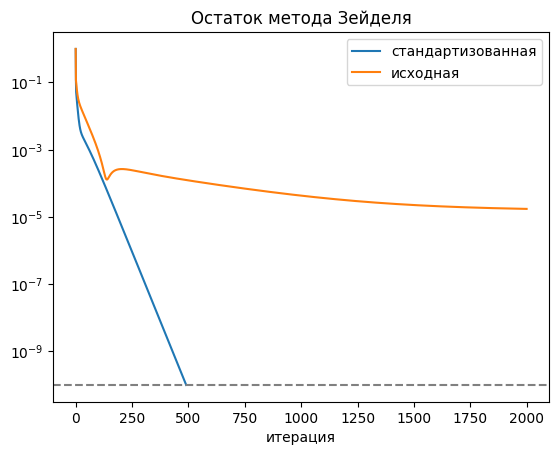

,||beta||,остаток НУ,остаток МНК,RMSE train,RMSE test
Зейдель,2.638,9.743e-11,0.2923,0.6936,0.7013
"Зейдель, исходные",0.8533,1.713e-05,0.3141,0.7452,0.7532


In [7]:
beta_seidel, hist = seidel(A, b)
beta_seidel_raw, hist_raw = seidel(A_raw, b_raw)
print('стандартизованная: итераций', len(hist) - 1, '| скорость', (hist[-1] / hist[-101]) ** 0.01)
print('исходная: итераций', len(hist_raw) - 1, '| остаток', hist_raw[-1])

plt.semilogy(hist, label='стандартизованная'); plt.semilogy(hist_raw, label='исходная')
plt.axhline(1e-10, ls='--', c='gray'); plt.title('Остаток метода Зейделя'); plt.xlabel('итерация'); plt.legend(); plt.show()
pd.DataFrame({'Зейдель': metrics(beta_seidel), 'Зейдель, исходные': metrics(beta_seidel_raw, X_raw, X_raw_te)}).T

**Сравнение с прогнозом.** Для стандартизованной матрицы ($\rho=0.963$) прогноз ~600 итераций, фактически 490. Скорость убывания остатка совпадает с $\rho$. Для исходной матрицы ($\rho=0.99996$) прогноз ~570 000 итераций, поэтому метод остановлен по лимиту 2000; RMSE хуже (0.753 против 0.701). Прогноз подтвердился.

### 4.3 SVD

Ранг определяем по правилу из п. 1, решение $\beta=V_r\Sigma_r^{-1}U_r^Ty$.

In [8]:
def svd_solve(X, y):
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    r = rank(s, X.shape)
    return Vt[:r].T @ (U[:, :r].T @ y / s[:r])

beta_svd = svd_solve(X, y)
sol = {'Гаусс': beta_gauss, 'Холецкий': beta_chol, 'Зейдель': beta_seidel, 'SVD': beta_svd}
tbl = pd.DataFrame({k: metrics(v) for k, v in sol.items()}).T
tbl['отличие от SVD'] = [np.linalg.norm(v - beta_svd) / np.linalg.norm(beta_svd) for v in sol.values()]
tbl

,||beta||,остаток НУ,остаток МНК,RMSE train,RMSE test,отличие от SVD
Гаусс,2.638,1.41e-14,0.2923,0.6936,0.7013,1.98e-13
Холецкий,2.638,1.408e-14,0.2923,0.6936,0.7013,1.988e-13
Зейдель,2.638,9.743e-11,0.2923,0.6936,0.7013,3.017e-09
SVD,2.638,1.174e-15,0.2923,0.6936,0.7013,0


Все методы дают одинаковые остатки и RMSE. Гаусс и Холецкий отличаются от SVD на ~$10^{-13}$ (ошибки округления), Зейдель — на ~$10^{-9}$ (допуск остановки).

## 5. Ухудшение обусловленности

Добавляем признак $x_{new}=x_{\text{medianIncome}}+0.5\,x_{\text{housingMedianAge}}+\varepsilon z$, где $z$ — фиксированный случайный вектор с единичной дисперсией. Ошибки методов перехватываются, поэтому ноутбук не прерывается.

In [9]:
rng = np.random.default_rng(SEED)
z, z_te = rng.standard_normal(n), rng.standard_normal(len(y_te))
new = lambda F, z, eps: F[:, 7] + 0.5 * F[:, 2] + eps * z  # medianIncome + 0.5 * housingMedianAge

rows = []
for eps in [1e-2, 1e-6, 0]:
    Xd, Xd_te = np.column_stack([X, new(F, z, eps)]), np.column_stack([X_te, new(F_te, z_te, eps)])
    s = np.linalg.svd(Xd, compute_uv=False)
    for method in ['Гаусс', 'SVD']:
        row = {'eps': eps, 'метод': method, 'ранг': rank(s, Xd.shape), 'kappa(X)': s[0] / s[-1]}
        try:
            beta = gauss(Xd.T @ Xd, Xd.T @ y) if method == 'Гаусс' else svd_solve(Xd, y)
            row.update(metrics(beta, Xd, Xd_te))
            row['статус'] = 'ненадёжно: kappa(A) > 1/eps' if method == 'Гаусс' and (s[0] / s[-1]) ** 2 > 1 / EPS else 'успех'
        except np.linalg.LinAlgError as e:
            row['статус'] = f'ошибка: {e}'
        rows.append(row)
degr = pd.DataFrame(rows).set_index(['eps', 'метод']).drop(columns='остаток НУ')
degr

ранг  kappa(X)  ||beta||  остаток МНК  RMSE train  RMSE test  \
eps   метод                                                                 
0.01  Гаусс    10     296.6     2.717       0.2923      0.6936     0.7013   
      SVD      10     296.6     2.717       0.2923      0.6936     0.7013   
1e-06 Гаусс    10 2.966e+06      2998       0.2923      0.6936     0.7013   
      SVD      10 2.966e+06      2984       0.2923      0.6936     0.7013   
0     Гаусс     9 4.619e+15     2.601       0.2923      0.6936     0.7013   
      SVD       9 4.619e+15     2.576       0.2923      0.6936     0.7013   

                                  статус  
eps   метод                               
0.01  Гаусс                        успех  
      SVD                          успех  
1e-06 Гаусс                        успех  
      SVD                          успех  
0     Гаусс  ненадёжно: kappa(A) > 1/eps  
      SVD                          успех

**Вывод.**
* $\varepsilon=10^{-2}$: $\kappa(X)\approx300$, всё работает, коэффициенты почти прежние.
* $\varepsilon=10^{-6}$: $\kappa(X)\approx3\cdot10^6$. Методы отработали, но $\|\beta\|$ выросла с 2.6 до ~3000: огромные веса разных знаков взаимно сокращаются. Гаусс и SVD уже немного расходятся.
* $\varepsilon=0$: ранг 9 из 10. Гаусс досчитал только из-за ошибок округления, но $\kappa(A)>1/\varepsilon$, и его результат ненадёжен. SVD отбросил нулевое направление и дал решение минимальной нормы.
* Остаток и RMSE не меняются (0.7013): портятся коэффициенты, а не прогноз.

## 6. Сокращение размерности и регуляризация

### 6.1 PCR

PCA обучаем на train. Для $k=1,2,3$ и полного ранга 8 решаем МНК по первым $k$ компонентам.

In [10]:
pca = PCA().fit(F)
Z, Z_te = pca.transform(F), pca.transform(F_te)
rows = []
for k in [1, 2, 3, 8]:
    Xk, Xk_te = ones(Z[:, :k]), ones(Z_te[:, :k])
    beta = svd_solve(Xk, y)
    rows.append({'k': k, 'доля дисперсии': pca.explained_variance_ratio_[:k].sum(), 'kappa': np.linalg.cond(Xk),
                 'RMSE train': rmse(y, Xk @ beta), 'RMSE test': rmse(y_te, Xk_te @ beta)})
pcr = pd.DataFrame(rows).set_index('k')
print('Корреляция компонент с y:', np.round([np.corrcoef(Z[:, i], y)[0, 1] for i in range(8)], 2))
pcr

Корреляция компонент с y: [ 0.06 -0.05  0.55  0.46 -0.12 -0.3   0.09  0.03]


,доля дисперсии,kappa,RMSE train,RMSE test
k,,,,
1,0.488,1.976,1.154,1.142
2,0.7269,1.976,1.152,1.14
3,0.8613,1.976,0.9579,0.9604
8,1,16.3,0.6936,0.7013


**Вывод.** Компоненты ортогональны, поэтому $\kappa\approx2$ при $k\le3$ (против 16 при $k=8$). Но ошибка выросла: при $k=1,2$ RMSE ≈ 1.14, как у константы. PCA выбирает направления с наибольшим разбросом признаков, а не самые полезные для $y$: сильнее всего с откликом связаны PC3 и PC4. При $k=3$ RMSE = 0.96, при $k=8$ совпадает с МНК.

### 6.2 Ridge

Решаем $(X^TX+\lambda D^TD)\beta=X^Ty$, где $D=\mathrm{diag}(0,1,\dots,1)$ не штрафует свободный член. Берём 7 значений $\lambda$ от 0.1 до $10^5$.

**Правило выбора (задано заранее):** $\lambda$ с минимальным RMSE на 5-кратной кросс-валидации по train.

Выбрано lambda = 10.0


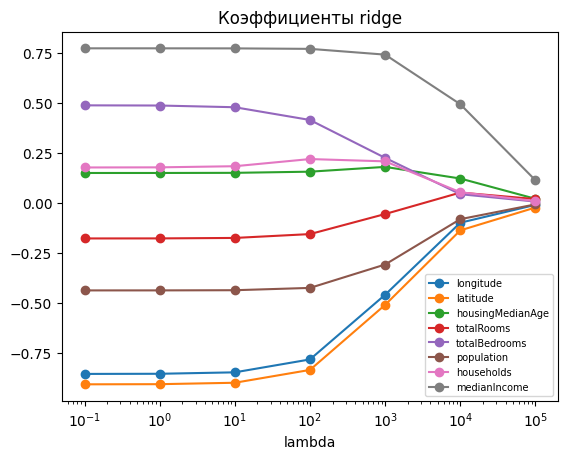

,kappa,||beta||,RMSE train,RMSE test,CV RMSE
lambda,,,,,
0.1,265.7,2.637,0.6936,0.7013,0.6949
1,264.7,2.637,0.6936,0.7013,0.6949
10,255.3,2.631,0.6936,0.7013,0.6949
100,188.5,2.577,0.6943,0.7018,0.6956
1000,52.69,2.353,0.7152,0.7215,0.7216
1e+04,7.27,2.143,0.838,0.8372,0.8599
1e+05,9.961,2.075,1.072,1.063,1.086


In [11]:
D = np.diag([0] + [1] * (p - 1))
LAMBDAS = [0.1, 1, 10, 100, 1e3, 1e4, 1e5]
ridge = lambda X, y, lam: gauss(X.T @ X + lam * D, X.T @ y)  # D^T D = D

folds = list(KFold(5, shuffle=True, random_state=SEED).split(X))
rows, betas = [], []
for lam in LAMBDAS:
    beta = ridge(X, y, lam)
    betas.append(beta)
    cv = np.mean([rmse(y[va], X[va] @ ridge(X[tr], y[tr], lam)) for tr, va in folds])
    rows.append({'lambda': lam, 'kappa': np.linalg.cond(A + lam * D), '||beta||': np.linalg.norm(beta),
                 'RMSE train': rmse(y, X @ beta), 'RMSE test': rmse(y_te, X_te @ beta), 'CV RMSE': cv})
ridge_tbl = pd.DataFrame(rows).set_index('lambda')
best = ridge_tbl['CV RMSE'].idxmin()
print('Выбрано lambda =', best)

plt.semilogx(LAMBDAS, np.array(betas)[:, 1:], 'o-'); plt.legend(FEATURES, fontsize=7)
plt.title('Коэффициенты ridge'); plt.xlabel('lambda'); plt.show()
ridge_tbl

**Вывод.**
* С ростом $\lambda$ обусловленность падает с 266 до ≈7. При $\lambda=10^5$ она снова чуть растёт: наименьшим становится нештрафуемое собственное число свободного члена.
* Коэффициенты сжимаются к нулю.
* RMSE почти не меняется до $\lambda\approx100$, дальше модель недообучается.
* Выбрано $\lambda=10$ — почти обычный МНК: задача и так хорошо обусловлена ($n\gg p$).

## 7. Итоговое сравнение

In [12]:
final = pd.DataFrame({k: metrics(v) for k, v in sol.items()}).T
final.loc[f'Ridge, lambda={best:g}'] = metrics(betas[LAMBDAS.index(best)])
final.loc['PCR, k=3', ['RMSE train', 'RMSE test']] = pcr.loc[3, ['RMSE train', 'RMSE test']].values
print('Исходная задача'); display(final)

print('Влияние стандартизации')
display(pd.DataFrame({
    'kappa(X^T X)': [np.linalg.cond(A_raw), np.linalg.cond(A)],
    'rho Зейделя': [rho(A_raw), rho(A)],
    'итераций Зейделя': [len(hist_raw) - 1, len(hist) - 1],
    'RMSE test, Гаусс': [rmse(y_te, X_raw_te @ gauss(A_raw, b_raw)), rmse(y_te, X_te @ beta_gauss)],
    'RMSE test, Зейдель': [rmse(y_te, X_raw_te @ beta_seidel_raw), rmse(y_te, X_te @ beta_seidel)]},
    index=['исходные', 'стандартизованные']).style.format({'rho Зейделя': '{:.6f}'}))

print('Ухудшенная задача'); display(degr)

Исходная задача


,||beta||,остаток НУ,остаток МНК,RMSE train,RMSE test
Гаусс,2.638,1.41e-14,0.2923,0.6936,0.7013
Холецкий,2.638,1.408e-14,0.2923,0.6936,0.7013
Зейдель,2.638,9.743e-11,0.2923,0.6936,0.7013
SVD,2.638,1.174e-15,0.2923,0.6936,0.7013
"Ridge, lambda=10",2.631,0.0004386,0.2923,0.6936,0.7013
"PCR, k=3",NaN,NaN,NaN,0.9579,0.9604


Влияние стандартизации


,kappa(X^T X),rho Зейделя,итераций Зейделя,"RMSE test, Гаусс","RMSE test, Зейдель"
исходные,258767082952.958008,0.999959,2000,0.701324,0.753204
стандартизованные,265.816300,0.962632,490,0.701324,0.701324


Ухудшенная задача


ранг  kappa(X)  ||beta||  остаток МНК  RMSE train  RMSE test  \
eps   метод                                                                 
0.01  Гаусс    10     296.6     2.717       0.2923      0.6936     0.7013   
      SVD      10     296.6     2.717       0.2923      0.6936     0.7013   
1e-06 Гаусс    10 2.966e+06      2998       0.2923      0.6936     0.7013   
      SVD      10 2.966e+06      2984       0.2923      0.6936     0.7013   
0     Гаусс     9 4.619e+15     2.601       0.2923      0.6936     0.7013   
      SVD       9 4.619e+15     2.576       0.2923      0.6936     0.7013   

                                  статус  
eps   метод                               
0.01  Гаусс                        успех  
      SVD                          успех  
1e-06 Гаусс                        успех  
      SVD                          успех  
0     Гаусс  ненадёжно: kappa(A) > 1/eps  
      SVD                          успех

### Ответы на вопросы

1. **Стандартизация** уменьшила $\kappa(X^TX)$ с $2.6\cdot10^{11}$ до 266. Гаусс справился в обоих случаях, а Зейдель без стандартизации не сошёлся за 2000 итераций ($\rho\approx1$), со стандартизацией — сошёлся за 490.
2. **Решения совпали:** RMSE и остатки одинаковы. Гаусс и SVD отличаются на ~$10^{-13}$ (округление), Зейдель — на ~$10^{-9}$ (допуск).
3. **Сходимость Зейделя** соответствует прогнозу: остаток убывает со скоростью $\rho$, итераций около оценки.
4. **При потере ранга** $\kappa$ растёт как $1/\varepsilon$, а коэффициенты — до ~3000. Решение Гаусса при $\varepsilon=0$ ненадёжно, SVD работает всегда. Прогноз не портится.
5. **PCR** улучшает обусловленность (16 → 2), но увеличивает ошибку (0.70 → 0.96–1.14): главные по дисперсии компоненты слабо связаны с $y$.
6. **Ridge:** с ростом $\lambda$ обусловленность улучшается, коэффициенты сжимаются, ошибка сначала стабильна, затем растёт. Выбрано $\lambda=10$.
7. **Лучший способ:** после стандартизации все методы равноценны, быстрее всего Холецкий. Самый надёжный — SVD: он работает с $\kappa(X)$, а не с $\kappa(X)^2$, и корректен при потере ранга.

## 8. Вклад участников

| Участник | Математика | Реализация | Эксперименты | Визуализация | Анализ | Отчёт |
|---|---|---|---|---|---|---|
| _ФИО 1_ | | | | | | |
| _ФИО 2_ | | | | | | |
| _ФИО 3_ | | | | | | |

**Источники:** Pace, Barry (1997) — данные; Golub, Van Loan. *Matrix Computations* — Гаусс, Холецкий, SVD; Saad. *Iterative Methods for Sparse Linear Systems* — метод Зейделя; Hastie и др. *The Elements of Statistical Learning* — ridge, PCR; документация NumPy, SciPy, scikit-learn. Методы Гаусса и Зейделя написаны по схемам из этих книг, остальные разложения взяты из библиотек.